# 01 · Exploratory data analysis

What the College Hockey News data says about winning college hockey games, before any model is built. The goal is to settle the decisions behind the **win-probability model** (project outline §4.1): what to predict, what baseline to beat, and which features are worth building.

**Data:** every D-I men's game from 2021-22 through the current season, scraped from College Hockey News and checked by [`validate_chn_data.py`](../src/evaluation/validate_chn_data.py) (see the [validation report](../docs/data_validation.md)).

**Planned split** (time-based, never random): train 2021-22 to 2023-24, tune on 2024-25, test once on 2025-26. 2026-27 is the live season.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data/processed/chn"

# Validated categorical palette (max 3 series per chart), quiet axes
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.figsize": (8, 3.8), "figure.dpi": 110,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "lines.linewidth": 2, "lines.markersize": 8, "legend.frameon": False, "font.size": 10,
})
pd.set_option("display.precision", 3)


def load(name):
    return pd.concat(
        [pd.read_csv(p) for p in sorted(DATA.glob(f"{name}_20*.csv"))], ignore_index=True
    )


def pct(ax, axis="y"):
    fmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


all_games, box_games, team_stats = load("all_games"), load("box_games"), load("box_team_stats")
goals_list, goalies = load("box_goals"), load("box_goalies")

**Two working tables.** `games` has one row per game with the result from the home team's side; `tg` has one row per team per game. A result is scored 1 for a win (regulation or overtime), 0 for a loss and **0.5 for a tie**. NCAA records a shootout game as a tie, so shootouts score 0.5 too. Games against non-D-I opponents are dropped: CHN records almost nothing about the other team.

In [2]:
games = all_games[all_games["is_played"]].merge(
    box_games[["game_id", "ot_periods", "shootout_winner"]], on="game_id", how="left"
)
games["date"] = pd.to_datetime(games["date"])
games["d1"] = games["home_team_id"].notna() & games["away_team_id"].notna()
games["home_result"] = np.select(
    [games["home_goals"] > games["away_goals"], games["home_goals"] < games["away_goals"]],
    [1.0, 0.0], 0.5,
)
games["ending"] = np.select(
    [games["shootout_winner"].notna(), games["home_goals"] == games["away_goals"],
     games["ot_periods"] > 0],
    ["Shootout", "Tie", "Overtime"], "Regulation",
)
print(f"{len(games):,} played games; {(~games['d1']).sum()} involve a non-D-I team and are dropped.")
games = games[games["d1"]].copy()

tg = team_stats.drop(columns="date").merge(
    games[["game_id", "season", "date", "is_neutral", "is_conference",
           "home_conference", "away_conference", "ending"]],
    on=["game_id", "season"],
)
tg["result"] = np.select(
    [tg["goals"] > tg["goals_against"], tg["goals"] < tg["goals_against"]], [1.0, 0.0], 0.5
)
tg["gd"] = tg["goals"] - tg["goals_against"]
tg["conference"] = np.where(tg["is_home"], tg["home_conference"], tg["away_conference"])
tg = tg.sort_values(["team", "date", "game_id"]).reset_index(drop=True)
print(f"{len(games):,} games, {len(tg):,} team-games")

5,873 played games; 18 involve a non-D-I team and are dropped.
5,855 games, 11,710 team-games


## 1. What's in the data

In [3]:
coverage = tg.groupby("season").agg(
    teams=("team", "nunique"),
    games=("game_id", "nunique"),
    goals_per_game=("goals", lambda s: 2 * s.mean()),
    shots_per_team=("shots", "mean"),
    pp_pct=("pp_goals", lambda s: s.sum() / tg.loc[s.index, "pp_opportunities"].sum()),
    has_xg=("xg", lambda s: s.notna().mean()),
)
coverage.style.format({"goals_per_game": "{:.2f}", "shots_per_team": "{:.1f}",
                       "pp_pct": "{:.1%}", "has_xg": "{:.0%}"})

,teams,games,goals_per_game,shots_per_team,pp_pct,has_xg
season,,,,,,
2021-22,59,1084,5.65,29.3,19.6%,0%
2022-23,62,1120,5.73,29.5,19.4%,0%
2023-24,64,1170,5.96,29.9,20.2%,0%
2024-25,64,1167,5.69,29.5,20.4%,100%
2025-26,63,1147,5.89,29.8,19.8%,100%
2026-27,56,167,5.83,29.9,19.0%,100%


About 1,100 to 1,170 games a season across 59 to 64 teams; 2026-27 is in progress. The scoring environment is steady (5.7 to 6.0 goals per game, about 30 shots per team, power plays converting near 20%), so seasons can be pooled without adjusting for scoring levels. xG (expected goals) exists only from 2024-25, so an xG feature can't be trained on the earlier seasons.

## 2. How games end

This decides the prediction target. If shootouts and ties were rare, they could be dropped.

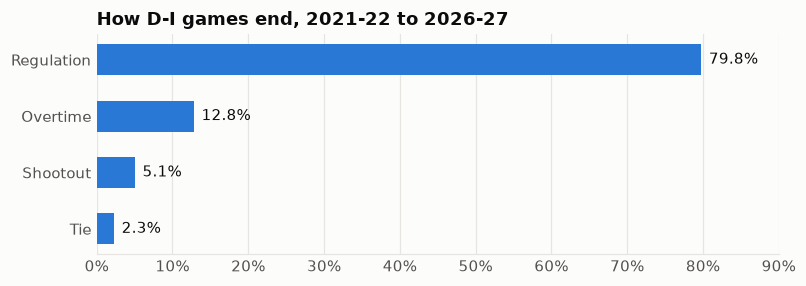

ending,Regulation,Overtime,Shootout,Tie
season,,,,
2021-22,81.3%,12.3%,4.4%,2.0%
2022-23,79.5%,13.3%,5.1%,2.1%
2023-24,78.5%,13.0%,5.6%,2.9%
2024-25,77.8%,14.1%,5.8%,2.3%
2025-26,81.8%,11.3%,4.9%,2.0%
2026-27,82.0%,14.4%,0.6%,3.0%


In [4]:
endings = games["ending"].value_counts(normalize=True).reindex(
    ["Regulation", "Overtime", "Shootout", "Tie"])

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(endings.index[::-1], endings.values[::-1], color=BLUE, height=0.55)
for y, v in enumerate(endings.values[::-1]):
    ax.text(v + 0.01, y, f"{v:.1%}", va="center", color=INK)
ax.set_title("How D-I games end, 2021-22 to 2026-27")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
pct(ax, "x"); ax.set_xlim(0, 0.9)
plt.show()

pd.crosstab(games["season"], games["ending"], normalize="index")[
    ["Regulation", "Overtime", "Shootout", "Tie"]].style.format("{:.1%}")

**About 7% of games end level** (shootout or tie), consistently every season. Dropping them would throw away a meaningful share of games and bias the model toward decisive results. **Decision: predict the home team's expected result, with ties and shootouts scored 0.5.** A predicted 0.60 then means "the home team averages 0.6 of a win in games like this".

## 3. Home ice, and the baseline to beat

Neutral-site games (tournaments, showcases) are excluded here.

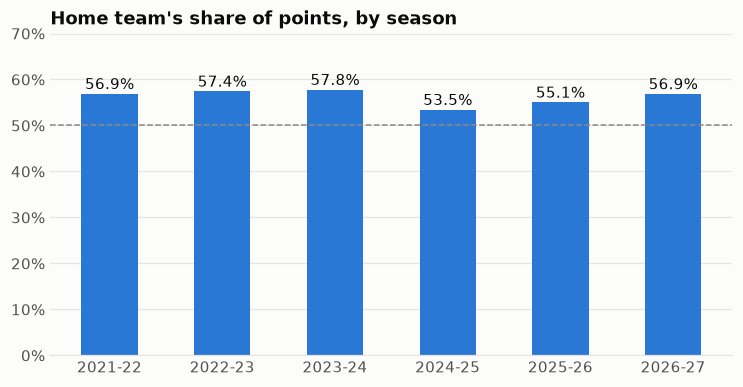

All seasons: home teams earn 56.1% of points over 5,578 games; neutral-site games: 277


In [5]:
home = games[~games["is_neutral"]]
by_season = home.groupby("season")["home_result"].mean()

fig, ax = plt.subplots()
ax.bar(by_season.index, by_season.values, color=BLUE, width=0.5)
ax.axhline(0.5, color=MUTED, linewidth=1, linestyle="--")
for x, v in enumerate(by_season.values):
    ax.text(x, v + 0.01, f"{v:.1%}", ha="center", color=INK)
ax.set_ylim(0, 0.7); ax.set_yticks(np.arange(0, 0.71, 0.1)); pct(ax)
ax.set_title("Home team's share of points, by season")
plt.show()
print(f"All seasons: home teams earn {home['home_result'].mean():.1%} of points "
      f"over {len(home):,} games; neutral-site games: {games['is_neutral'].sum():,}")

The home edge is real but modest, about 56% of points, and it moves a few points from year to year (2024-25 was the weakest at 53.5%).

**Baseline Brier scores.** Brier score is the mean squared error of a probability; lower is better. (Predicting 0.5 scores 0.25 on a decided game and 0 on a tie.) The simplest baseline predicts the home team's average result from the training seasons for every game.

In [6]:
train = home[home["season"].isin(["2021-22", "2022-23", "2023-24"])]
home_rate = train["home_result"].mean()


def brier(p, y):
    return float(np.mean((p - y) ** 2))


rows = []
for season in ["2024-25", "2025-26"]:
    y = home.loc[home["season"] == season, "home_result"]
    rows.append({"season": season, "games": len(y),
                 "coin flip (0.5)": brier(0.5, y),
                 f"home rate from training ({home_rate:.3f})": brier(home_rate, y)})
baselines = pd.DataFrame(rows).set_index("season")
baselines.style.format("{:.4f}", subset=baselines.columns[1:])

,games,coin flip (0.5),home rate from training (0.574)
season,,,
2024-25,1100,0.2291,0.2295
2025-26,1089,0.2323,0.2303


**Home ice alone is not a usable baseline.** The training seasons' home rate (57.4%) does no better than a coin flip on 2024-25, when the home edge dipped, and only slightly better on 2025-26. The home edge is too small and too variable to predict games by itself. The real floor for the models is the **Elo baseline**, which adds team strength; home ice becomes one fitted parameter inside it.

## 4. When goals are scored

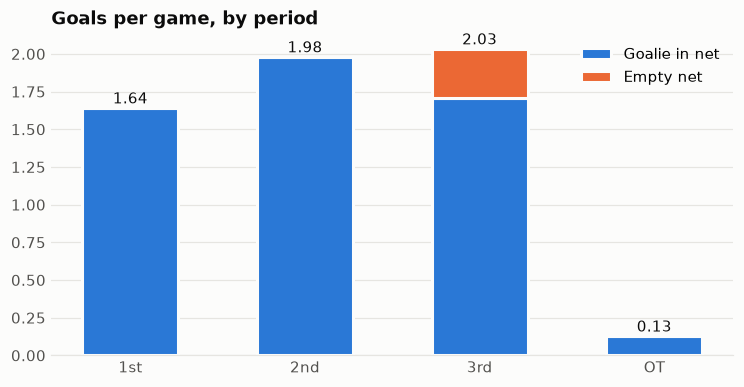

In [7]:
per_period = (
    goals_list[goals_list["game_id"].isin(games["game_id"])]
    .assign(kind=lambda d: np.where(d["is_en"], "Empty net", "Goalie in net"))
    .groupby(["period", "kind"]).size().unstack(fill_value=0) / len(games)
)
per_period.index = ["1st", "2nd", "3rd", "OT"]

fig, ax = plt.subplots()
x = np.arange(len(per_period))
ax.bar(x, per_period["Goalie in net"], width=0.55, color=BLUE, label="Goalie in net",
       edgecolor=SURFACE, linewidth=2)
ax.bar(x, per_period["Empty net"], width=0.55, bottom=per_period["Goalie in net"],
       color=ORANGE, label="Empty net", edgecolor=SURFACE, linewidth=2)
for i, total in enumerate(per_period.sum(axis=1)):
    ax.text(i, total + 0.03, f"{total:.2f}", ha="center", color=INK)
ax.set_xticks(x, per_period.index)
ax.set_title("Goals per game, by period")
ax.legend(loc="upper right")
plt.show()

With a goalie in net, the **2nd period** has the most goals (the long change makes defensive zone exits harder). The 3rd only edges ahead once **empty-net goals** are added, about a third of a goal per game. That matters for features: empty-net goals are scored by teams that are already winning, so they pad goal differential without saying much more about strength. **Goal differential without empty-net goals** is the cleaner measure. Overtime adds little per game because only 13% of games reach it.

## 5. What goes with winning (in the same game)

How a team's share of each stat in a game relates to its result *in that game*. This is descriptive, not predictive (it uses the game's own numbers), but it shows which stats are worth averaging over past games as features.

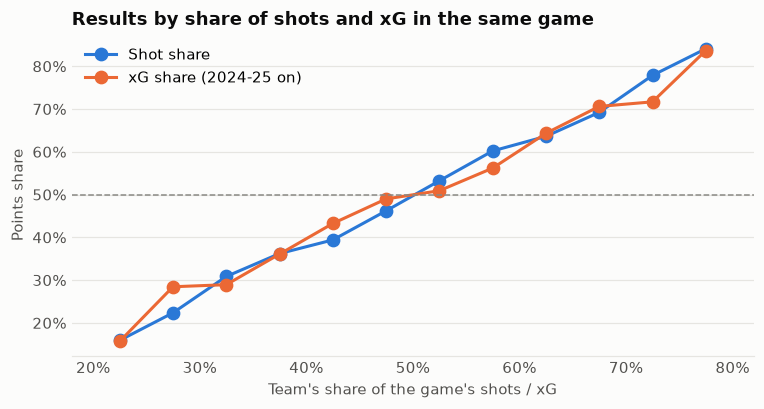

,"correlation with result, 2024-25 on"
xg_share,0.252
shot_share,0.252
pp_goal_diff,0.396
faceoff_share,0.094


In [8]:
tg["shot_share"] = tg["shots"] / (tg["shots"] + tg["shots_against"])
tg["xg_share"] = tg["xg"] / (tg["xg"] + tg["xg_against"])
tg["faceoff_share"] = tg["faceoffs_won"] / (tg["faceoffs_won"] + tg["faceoffs_lost"])
tg["pp_goal_diff"] = tg["pp_goals"] - tg["pp_goals_against"]

bins = np.arange(0.20, 0.81, 0.05)
fig, ax = plt.subplots()
for col, label, color in [("shot_share", "Shot share", BLUE), ("xg_share", "xG share (2024-25 on)", ORANGE)]:
    d = tg.dropna(subset=[col])
    grp = d.groupby(pd.cut(d[col], bins), observed=True)["result"].agg(["mean", "size"])
    grp = grp[grp["size"] >= 30]
    mids = [b.mid for b in grp.index]
    ax.plot(mids, grp["mean"], marker="o", color=color, label=label)
ax.axhline(0.5, color=MUTED, linewidth=1, linestyle="--")
pct(ax); pct(ax, "x")
ax.set_xlabel("Team's share of the game's shots / xG")
ax.set_ylabel("Points share")
ax.set_xlim(0.18, 0.82)
ax.set_title("Results by share of shots and xG in the same game")
ax.legend(loc="upper left")
plt.show()

both = tg.dropna(subset=["xg_share"])  # same games for every stat: 2024-25 on
corr = {col: both[col].corr(both["result"]) for col in
        ["xg_share", "shot_share", "pp_goal_diff", "faceoff_share"]}
pd.Series(corr, name="correlation with result, 2024-25 on").to_frame().style.format("{:.3f}")

On the same games, **xG share and shot share go with winning about equally**, so CHN's xG adds little over plain shot counts at the team level (and it only exists from 2024-25). **Power-play goal difference has the strongest link**, partly because power-play goals are goals, but it also says special teams decide a lot of games. Faceoffs barely matter. For features: shot share (available every season), special-teams results, and xG only if it earns its place.

## 6. Does past form predict the next game?

The first real feature check. For every game, each team's numbers *before* the game: season-to-date goal differential per game, and the last 5 games' goal differential. Then the home team's result, grouped by the gap between the two teams. Both teams need at least 5 earlier games, so both measures use the same games.

4,532 non-neutral games where both teams have 5+ earlier games


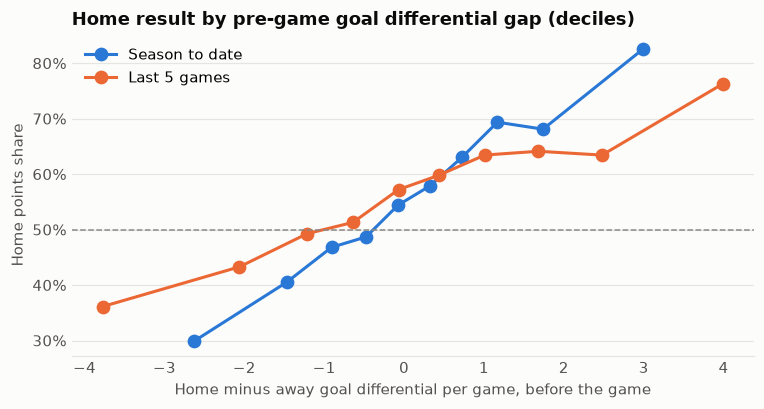

,correlation with home result
gd_season,0.310
gd_last5,0.240
shot_share_season,0.318


In [9]:
grp = tg.groupby(["team", "season"])
tg["games_before"] = grp.cumcount()
tg["gd_season"] = grp["gd"].transform(lambda s: s.shift().expanding().mean())
tg["gd_last5"] = grp["gd"].transform(lambda s: s.shift().rolling(5).mean())
tg["shot_share_season"] = grp["shot_share"].transform(lambda s: s.shift().expanding().mean())

pre = tg.pivot_table(index="game_id", columns="is_home",
                     values=["gd_season", "gd_last5", "shot_share_season"])
diff = pd.DataFrame({c: pre[(c, True)] - pre[(c, False)] for c in
                     ["gd_season", "gd_last5", "shot_share_season"]})
pg = home.set_index("game_id")[["season", "home_result"]].join(diff, how="inner").dropna()
print(f"{len(pg):,} non-neutral games where both teams have 5+ earlier games")

fig, ax = plt.subplots()
for col, label, color in [("gd_season", "Season to date", BLUE), ("gd_last5", "Last 5 games", ORANGE)]:
    b = pg.groupby(pd.qcut(pg[col], 10), observed=True).agg(x=(col, "mean"), y=("home_result", "mean"))
    ax.plot(b["x"], b["y"], marker="o", color=color, label=label)
ax.axhline(0.5, color=MUTED, linewidth=1, linestyle="--")
pct(ax)
ax.set_xlabel("Home minus away goal differential per game, before the game")
ax.set_ylabel("Home points share")
ax.set_title("Home result by pre-game goal differential gap (deciles)")
ax.legend(loc="upper left")
plt.show()

pd.Series({c: pg[c].corr(pg["home_result"]) for c in diff.columns},
          name="correlation with home result").to_frame().style.format("{:.3f}")

There is clear signal: the home team's points share climbs steadily across the deciles. **Season-to-date form beats last-5 form** (correlation 0.31 vs 0.24): a five-game window is mostly noise. **Season-to-date shot share predicts as well as goal differential** (0.32), even though it ignores goals: shots are far more frequent than goals, so they settle faster. So the core features should be long-window (or exponentially weighted) averages of both, and a short "hot streak" window has to earn its place.

## 7. How stable is team strength?

Two questions for the Elo baseline and for early-season games: how much of a team's strength carries into the next season, and how many games it takes before this season's results say more than last season's.

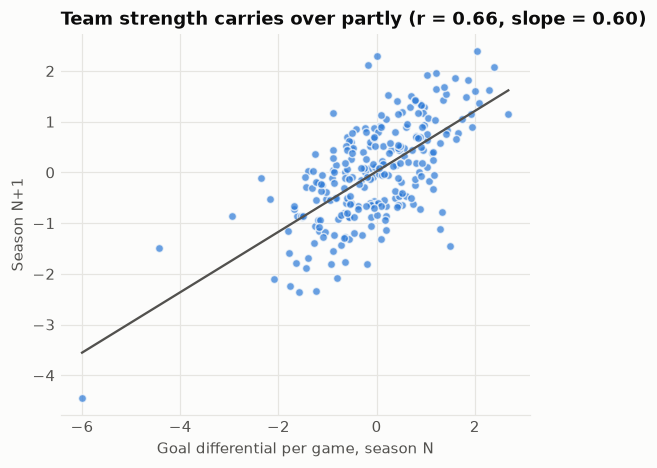

In [10]:
seasons = sorted(tg["season"].unique())
complete = seasons[:-1]  # the current season is still in progress
team_season = tg.groupby(["team", "season"])["gd"].mean().unstack()
pairs = pd.concat(
    [team_season[[a, b]].dropna().set_axis(["prev", "next"], axis=1)
     for a, b in zip(complete, complete[1:])]
)
slope, intercept = np.polyfit(pairs["prev"], pairs["next"], 1)
r = pairs["prev"].corr(pairs["next"])

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(pairs["prev"], pairs["next"], s=28, color=BLUE, alpha=0.7,
           edgecolor=SURFACE, linewidth=1)
xs = np.linspace(pairs["prev"].min(), pairs["prev"].max(), 10)
ax.plot(xs, intercept + slope * xs, color=INK_2, linewidth=1.5)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Goal differential per game, season N")
ax.set_ylabel("Season N+1")
ax.set_title(f"Team strength carries over partly (r = {r:.2f}, slope = {slope:.2f})")
plt.show()

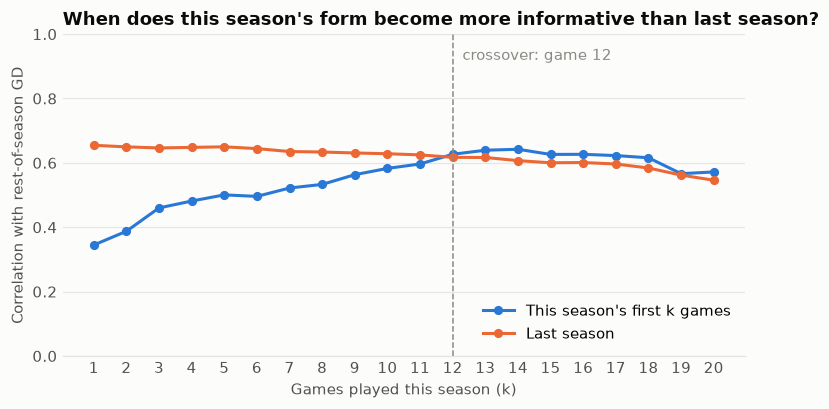

In [11]:
# For each k: how well do the first k games, or last season, predict the rest of this season?
rows = []
full = tg[tg["season"].isin(complete[1:])]  # needs a previous season
prev_gd = team_season.shift(1, axis=1)  # previous season's GD per game, same team
for k in range(1, 21):
    first = full[full["games_before"] < k].groupby(["team", "season"])["gd"].mean()
    rest = full[full["games_before"] >= k].groupby(["team", "season"])["gd"].mean()
    d = pd.DataFrame({"first": first, "rest": rest})
    d["prev"] = [prev_gd.at[t, s] for t, s in d.index]
    d = d.dropna()
    rows.append({"k": k, "This season's first k games": d["first"].corr(d["rest"]),
                 "Last season": d["prev"].corr(d["rest"])})
stab = pd.DataFrame(rows).set_index("k")

fig, ax = plt.subplots()
for col, color in [("This season's first k games", BLUE), ("Last season", ORANGE)]:
    ax.plot(stab.index, stab[col], color=color, marker="o", markersize=5, label=col)
cross = stab.index[stab.iloc[:, 0] > stab.iloc[:, 1]]
if len(cross):
    ax.axvline(cross[0], color=MUTED, linewidth=1, linestyle="--")
    ax.text(cross[0] + 0.3, 0.92, f"crossover: game {cross[0]}", color=MUTED)
ax.set_ylim(0, 1); ax.set_xticks(range(1, 21))
ax.set_xlabel("Games played this season (k)")
ax.set_ylabel("Correlation with rest-of-season GD")
ax.set_title("When does this season's form become more informative than last season?")
ax.legend(loc="lower right")
plt.show()

Strength carries over only partly between seasons: a team keeps about **60%** of last season's goal differential (slope 0.60, r = 0.66, 247 team-season pairs); the rest drifts back toward average with roster turnover. **For Elo, that means pulling ratings about 40% of the way back to the mean between seasons** (a starting point to tune, not a final value).

Within a season, last season's goal differential predicts the rest of this season better than this season's own results until about **game 12**, roughly mid-December. **Early-season features should blend last season's numbers in and fade them out by around 12 games**, rather than starting every team from zero. (Both lines fall past game 15 because the "rest of season" being predicted gets shorter.)

## 8. Weekend series

Most college games come in Friday-Saturday pairs against the same opponent, which generic sports models don't account for.

In [12]:
g = games.sort_values("date").copy()
g["pair"] = [tuple(sorted(p)) for p in zip(g["home_team"], g["away_team"])]
g["days_since_meeting"] = g.groupby("pair")["date"].diff().dt.days
g["series_game_2"] = g["days_since_meeting"] == 1
# result from the perspective of the alphabetically first team in the pair
g["first_result"] = np.where(g["home_team"] == g["pair"].str[0], g["home_result"], 1 - g["home_result"])
g["prev_first_result"] = g.groupby("pair")["first_result"].shift()

g2 = g[g["series_game_2"] & (g["first_result"] != 0.5) & (g["prev_first_result"] != 0.5)]
same_winner = (g2["first_result"] == g2["prev_first_result"]).mean()

nn = g[~g["is_neutral"]]
pd.DataFrame({
    "value": [f"{g['series_game_2'].mean():.1%}",
              f"{nn.loc[~nn['series_game_2'], 'home_result'].mean():.1%}",
              f"{nn.loc[nn['series_game_2'], 'home_result'].mean():.1%}",
              f"{same_winner:.1%}", f"{len(g2):,}"]},
    index=["Games that are game 2 of a back-to-back vs the same team",
           "Home points share, other games",
           "Home points share, game 2",
           "Game 1 winner also wins game 2 (decisive games only)",
           "Decisive game-2s"],
)

,value
Games that are game 2 of a back-to-back vs the same team,35.2%
"Home points share, other games",56.8%
"Home points share, game 2",55.0%
Game 1 winner also wins game 2 (decisive games only),58.5%
Decisive game-2s,"1,774"


About a third of all games are the second game of a series. The game 1 winner also wins game 2 58.5% of the time, which mostly reflects that the better team is the better team both nights; team strength should already capture it. The home edge is slightly smaller in game 2 (55.0% vs 56.8%). **Worth testing as features (`series_game_2`, `won_game_1`), not assuming they help.**

## 9. Rest

In [13]:
tg["rest_days"] = tg.groupby(["team", "season"])["date"].diff().dt.days
rest = tg.pivot_table(index="game_id", columns="is_home", values="rest_days")
rest_gap = (rest[True] - rest[False]).rename("rest_gap")
r = home.set_index("game_id")[["home_result"]].join(rest_gap, how="inner").dropna()
r["rest"] = pd.cut(r["rest_gap"], [-99, -1.5, -0.5, 0.5, 1.5, 99],
                   labels=["away 2+ days more", "away 1 day more", "same", "home 1 day more",
                           "home 2+ days more"])
r.groupby("rest", observed=True)["home_result"].agg(["mean", "size"]).rename(
    columns={"mean": "home points share", "size": "games"}).style.format({"home points share": "{:.1%}"})

,home points share,games
rest,,
away 2+ days more,57.6%,473
away 1 day more,52.2%,179
same,55.7%,4026
home 1 day more,53.9%,192
home 2+ days more,59.8%,480


Most games (about 75%) are played on equal rest. Where rest differs there's no consistent pattern: the home team does best with 2+ extra days (59.8%) but also does well when the *away* team has 2+ extra days (57.6%), and the 1-day groups have under 200 games each. **Rest shows no reliable effect here**; it can go into the model as a minor feature, but don't expect much from it.

## 10. Conference strength

Teams mostly play inside their conference, so a team's record partly reflects its conference. Non-conference games between D-I teams show how conferences compare.

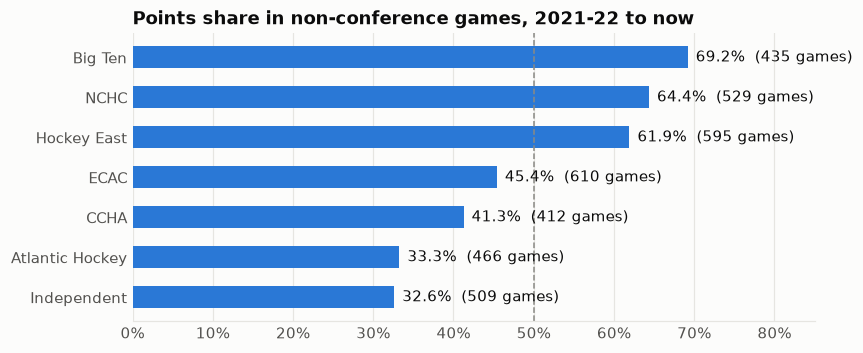

In [14]:
nc = tg[(~tg["is_conference"]) & (tg["home_conference"] != tg["away_conference"])]
conf = nc.groupby("conference")["result"].agg(["mean", "size"]).sort_values("mean")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(conf.index, conf["mean"], color=BLUE, height=0.55)
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--")
for y, (m, n) in enumerate(zip(conf["mean"], conf["size"])):
    ax.text(m + 0.01, y, f"{m:.1%}  ({n:,} games)", va="center", color=INK)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
pct(ax, "x"); ax.set_xlim(0, 0.85)
ax.set_title("Points share in non-conference games, 2021-22 to now")
plt.show()

The gaps are large. The Big Ten (69%), NCHC (64%) and Hockey East (62%) win well over half their non-conference games; ECAC (45%) and CCHA (41%) less; Atlantic Hockey and the independents only a third. So **a raw record or goal differential overstates teams in weak conferences**, and since most games are in-conference, only the non-conference games tie the conferences together. That's what strength-of-schedule adjustment, or Elo (which adjusts for opponent strength automatically), has to handle.

## 11. Goalie usage

For the report's goaltending section, and for whether a "who's starting" feature matters.

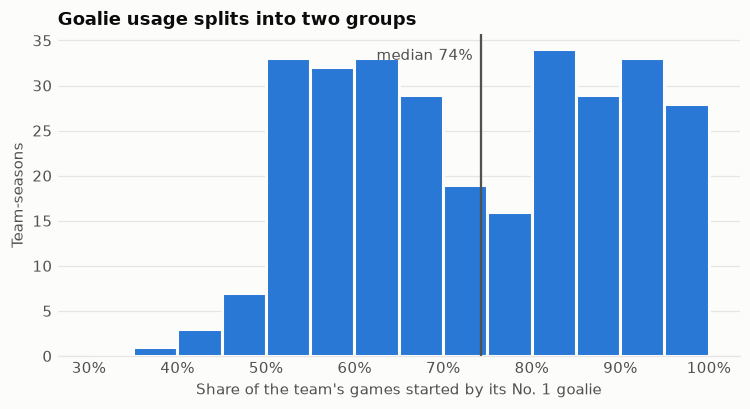

24% of team-seasons split starts (No. 1 starts under 60%)


In [15]:
starts = goalies[goalies["is_starter"] & goalies["game_id"].isin(games["game_id"])]
share = (starts.groupby(["team", "season"])["goalie"]
         .agg(lambda s: s.value_counts(normalize=True).iloc[0]))
share = share[share.index.get_level_values("season").isin(complete)]

fig, ax = plt.subplots()
ax.hist(share, bins=np.arange(0.3, 1.01, 0.05), color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.axvline(share.median(), color=INK_2, linewidth=1.5)
ax.text(share.median() - 0.01, ax.get_ylim()[1] * 0.92, f"median {share.median():.0%}",
        ha="right", color=INK_2)
pct(ax, "x")
ax.set_xlabel("Share of the team's games started by its No. 1 goalie")
ax.set_ylabel("Team-seasons")
ax.set_title("Goalie usage splits into two groups")
plt.show()
print(f"{(share < 0.6).mean():.0%} of team-seasons split starts (No. 1 starts under 60%)")

Goalie usage splits into two groups: teams that ride one goalie (80% or more of starts) and teams that platoon (50 to 65%). About **a quarter of team-seasons split the job** (No. 1 under 60% of starts). For those teams, who starts can swing a game, so a goalie-quality feature (the likely starter's save percentage) is worth building. Starters usually aren't announced in advance in college hockey, so the feature has to be an "expected starter" from recent usage.

## 12. Boston University in context

In [16]:
team_rank = tg.groupby(["season", "team"]).agg(
    gp=("result", "size"), wins=("result", lambda s: (s == 1).sum()),
    losses=("result", lambda s: (s == 0).sum()), ties=("result", lambda s: (s == 0.5).sum()),
    points_share=("result", "mean"), gd_per_game=("gd", "mean"),
    shot_share=("shot_share", "mean"),
)
team_rank["gd_rank"] = team_rank.groupby("season")["gd_per_game"].rank(ascending=False, method="min")
teams_n = team_rank.groupby("season").size().rename("teams")
bu = team_rank.xs("Boston University", level="team").join(teams_n)
bu["record"] = bu["wins"].astype(str) + "-" + bu["losses"].astype(str) + "-" + bu["ties"].astype(str)
bu["GD rank"] = bu["gd_rank"].astype(int).astype(str) + " of " + bu["teams"].astype(str)
bu[["gp", "record", "points_share", "gd_per_game", "shot_share", "GD rank"]].style.format(
    {"points_share": "{:.1%}", "gd_per_game": "{:+.2f}", "shot_share": "{:.1%}"})

,gp,record,points_share,gd_per_game,shot_share,GD rank
season,,,,,,
2021-22,35,19-13-3,58.6%,+0.51,53.0%,21 of 59
2022-23,40,29-11-0,72.5%,+1.20,54.9%,6 of 62
2023-24,40,28-10-2,72.5%,+1.65,54.0%,4 of 64
2024-25,40,24-14-2,62.5%,+0.78,49.6%,17 of 64
2025-26,36,17-17-2,50.0%,-0.14,50.7%,37 of 63
2026-27,6,4-2-0,66.7%,+1.17,57.9%,15 of 56


BU was a top-6 team by goal differential in 2022-23 and 2023-24, slipped to 17th in 2024-25 and to 37th (17-17-2) in 2025-26, and has started 2026-27 4-2. A swing like that is exactly what the stability numbers in section 7 describe, and why an early-season BU prediction should lean on more than last season.

## Takeaways for modeling

1. **Target:** the home team's expected result, with ties and shootouts scored 0.5. Level games are 7% of games every season, too many to drop.
2. **Baseline:** home ice alone barely beats a coin flip (home edge about 56%, varying from 53.5% to 57.8% by season). The floor to beat is an **Elo model**, with home ice as one of its fitted parameters.
3. **Elo settings to start from:** pull ratings about 40% back to the mean between seasons (teams keep about 60% of their goal differential). Conference gaps are large, and Elo's opponent adjustment is what handles them.
4. **Core features:** season-to-date shot share and goal differential (excluding empty-net goals), and special-teams results. Short windows (last 5) are weaker. Blend in last season's numbers for roughly the first 12 games.
5. **Features to test rather than assume:** xG share (only 2024-25 on, and no better than shot share here), weekend-series game 2 and "won last night", rest days, and the expected starting goalie's quality (a quarter of teams split starts).
6. **Evaluation:** Brier score and calibration on 2024-25 (tuning) and 2025-26 (test), with 2026-27 scored live as games are played.